# HV-013 — Final Engineering Assessment

**Technical gate:** FA-001

This notebook integrates the complete analyst-visible validation chain into a final requirement-by-requirement engineering assessment.

## 1. Final Engineering Question

> Is the sensor suitable for the intended HVAC measurement application, under the tested operating conditions, after calibration and with quantified measurement uncertainty?

The answer is separated into:

1. full public-spec compliance;
2. steady-state/static HVAC suitability;
3. dynamic HVAC suitability.

## 2. Reproducible Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "config" / "public" / "lab_spec_v1.json").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Could not locate project root.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.final_assessment import (
    build_application_risk_matrix,
    build_compliance_matrix,
    linearity_metric,
    load_final_evidence,
    load_frozen_c1_offset,
    load_public_spec,
    load_static_characterization,
    matched_static_hysteresis,
    summarize_characterization_tests,
    temperature_influence_metric,
)

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")

Project root: /home/runner/work/hvac-sensor-validation-metrology/hvac-sensor-validation-metrology


## 3. FA-01 — Public Acceptance-Limit Audit

All limits are loaded unchanged from the imported public laboratory specification.

In [2]:
public_spec = load_public_spec(project_root)
limits = public_spec["dut_public_spec"]["acceptance_limits"]

display(pd.DataFrame(
    [{"Requirement": k, "Public_Value": v} for k, v in limits.items()]
))

expected_keys = {
    "static_accuracy_abs_rh_percent",
    "repeatability_sigma_max_rh_percent",
    "hysteresis_max_rh_percent",
    "linearity_max_rh_percent",
    "temperature_influence_max_rh_percent_per_c",
    "t90_max_s",
    "settling_band_abs_rh_percent",
    "drift_max_rh_percent_per_year",
}
assert set(limits) == expected_keys

print("FA-01 public acceptance-limit audit: PASS")

,Requirement,Public_Value
0,static_accuracy_abs_rh_percent,2.00
1,repeatability_sigma_max_rh_percent,0.30
2,hysteresis_max_rh_percent,1.00
3,linearity_max_rh_percent,1.00
4,temperature_influence_max_rh_percent_per_c,0.05
5,t90_max_s,60.00
6,settling_band_abs_rh_percent,1.00
7,drift_max_rh_percent_per_year,0.80


FA-01 public acceptance-limit audit: PASS


## 4. FA-02 — Static Characterization Metrics

C1 is frozen and is not refit.

The characterization dataset is used to compute:

- strict maximum within-Test_ID repeatability;
- matched static hysteresis;
- project-defined best-fit linearity;
- RH-conditioned temperature influence.

In [3]:
c1_offset = load_frozen_c1_offset(project_root)
char_df, char_matrix_df = load_static_characterization(project_root)

static_test_summary_df = summarize_characterization_tests(
    char_df,
    char_matrix_df,
    c1_offset,
)

assert len(static_test_summary_df) == 120
assert static_test_summary_df["Test_ID"].nunique() == 120

hysteresis_df = matched_static_hysteresis(static_test_summary_df)
linearity_df, linearity_metrics = linearity_metric(static_test_summary_df)
temperature_influence_df, temperature_metrics = temperature_influence_metric(
    static_test_summary_df
)

print("Matched static hysteresis")
display(
    hysteresis_df.sort_values("Hysteresis_Abs", ascending=False).head(10).round(6)
)

print("Linearity by RH")
display(linearity_df.round(6))
print("Linearity metrics:", linearity_metrics)

print("Temperature influence by RH × Direction")
display(temperature_influence_df.round(6))
print("Temperature metrics:", temperature_metrics)

print("FA-02 static metrics: PASS")

Matched static hysteresis


,RH_Setpoint,Temperature_Setpoint_C,Day_ID,Run_ID,C1_MBE_UP,C1_MBE_DOWN,UP_Minus_DOWN,Hysteresis_Abs
48,70.0,25.0,2.0,1.0,-0.416988,0.508012,-0.925000,0.925000
18,40.0,15.0,3.0,1.0,-0.223821,0.694012,-0.917833,0.917833
34,50.0,35.0,2.0,1.0,-0.371488,0.546179,-0.917667,0.917667
43,70.0,15.0,1.0,2.0,-0.198321,0.711845,-0.910167,0.910167
9,30.0,15.0,2.0,2.0,-0.601155,0.302512,-0.903667,0.903667
55,80.0,15.0,3.0,2.0,-0.218321,0.681679,-0.900000,0.900000
59,80.0,35.0,3.0,2.0,-0.669988,0.224512,-0.894500,0.894500
21,40.0,25.0,3.0,2.0,-0.267988,0.623512,-0.891500,0.891500
12,30.0,25.0,2.0,1.0,-0.442321,0.444679,-0.887000,0.887000
57,80.0,25.0,3.0,2.0,-0.445821,0.438679,-0.884500,0.884500


Linearity by RH


,RH_Setpoint,Mean_C1_Residual,N_Test_IDs,Fitted_Residual,Linearity_Deviation,Linearity_Abs_Deviation
0,20.0,-0.046182,12,0.040808,-0.086990,0.086990
1,30.0,-0.000502,24,0.057970,-0.058472,0.058472
2,40.0,0.195998,12,0.075133,0.120865,0.120865
3,50.0,0.147068,24,0.092296,0.054772,0.054772
4,60.0,0.224929,12,0.109459,0.115470,0.115470
5,70.0,0.062207,24,0.126621,-0.064415,0.064415
6,80.0,0.062554,12,0.143784,-0.081230,0.081230


Linearity metrics: {'Slope_Per_RH': 0.001716269841269843, 'Intercept': 0.006482390873015197, 'Max_Abs_Deviation': 0.12086507936507954, 'RMS_Deviation': 0.08674721967266315}
Temperature influence by RH × Direction


,RH_Setpoint,Direction,Slope_RH_per_C,Abs_Slope_RH_per_C,Intercept,R2,Error_15C,Error_35C,Delta_35_minus_15
0,20.0,DOWN,0.012292,0.012292,0.051248,0.954311,0.220095,0.465929,0.245833
1,20.0,UP,0.010962,0.010962,-0.724967,0.989695,-0.554071,-0.334821,0.219250
2,30.0,DOWN,0.005854,0.005854,0.265630,0.963745,0.346887,0.463970,0.117083
3,30.0,UP,0.005277,0.005277,-0.544915,0.998148,-0.467071,-0.361530,0.105542
4,40.0,DOWN,-0.001437,0.001437,0.655450,0.357548,0.622762,0.594012,-0.028750
5,40.0,UP,-0.000437,0.000437,-0.216578,0.286503,-0.219155,-0.227905,-0.008750
6,50.0,DOWN,-0.004242,0.004242,0.671873,0.919702,0.601012,0.516179,-0.084833
7,50.0,UP,-0.006808,0.006808,-0.101488,0.998703,-0.202196,-0.338363,-0.136167
8,60.0,DOWN,-0.010121,0.010121,0.884311,0.998538,0.730262,0.527845,-0.202417
9,60.0,UP,-0.007387,0.007387,0.003255,0.998742,-0.109071,-0.256821,-0.147750


Temperature metrics: {'Max_Abs_Slope_RH_per_C': 0.02260833333333333, 'Worst_RH_Setpoint': 80.0, 'Worst_Direction': 'DOWN'}
FA-02 static metrics: PASS


## 5. FA-03 — Integrated Milestone Evidence Audit

In [4]:
evidence = load_final_evidence(project_root)

for key, table in evidence.items():
    assert len(table) > 0, f"Missing evidence table: {key}"

print("Loaded final evidence tables:")
for key, table in evidence.items():
    print(f"{key:24s}: {len(table):4d} rows")

print("FA-03 integrated milestone evidence audit: PASS")

Loaded final evidence tables:
rr_summary              :    5 rows
repeatability_detail    :  120 rows
validation_models       :    3 rows
validation_direction    :    2 rows
step_metrics            :   30 rows
step_overall            :    5 rows
ramp_summary            :    6 rows
cyclic_summary          :    3 rows
sinusoidal              :    4 rows
weekly_drift            :   13 rows
weekly_trend            :    2 rows
monthly_span            :    3 rows
uncertainty             :    4 rows
mc_summary              :    8 rows
FA-03 integrated milestone evidence audit: PASS


## 6. FA-04 — Public Requirement Compliance Matrix

Status vocabulary:

- PASS
- FAIL
- NOT_DEMONSTRATED
- INFORMATIONAL

No new threshold is introduced.

In [5]:
compliance_matrix_df = build_compliance_matrix(
    public_spec=public_spec,
    static_test_summary=static_test_summary_df,
    hysteresis_df=hysteresis_df,
    linearity_metrics=linearity_metrics,
    temp_metrics=temperature_metrics,
    evidence=evidence,
)

display(compliance_matrix_df)

allowed_status = {"PASS", "FAIL", "NOT_DEMONSTRATED", "INFORMATIONAL"}
assert set(compliance_matrix_df["Status"]).issubset(allowed_status)

print("Status counts")
display(
    compliance_matrix_df["Status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Count")
)

print("FA-04 public requirement matrix: PASS")

,Requirement,Public_Limit,Metric,Observed,Units,Status,Evidence,Notes
0,Static accuracy,±2.00 %RH,max(|residual bias| + U_k2) at declared uncert...,1.412933,%RH,PASS,HV-011,Applies to four declared uncertainty-evaluatio...
1,Repeatability sigma,≤ 0.30 %RH,pooled/common-sigma 95% UCL; strict worst-cond...,0.262903,%RH,NOT_DEMONSTRATED,HV-005 / audit review,Pooled SD=0.2593 %RH; one-sided 95% common-sig...
2,Static hysteresis,≤ 1.00 %RH,maximum matched |UP mean error - DOWN mean error|,0.925000,%RH,PASS,HV-004/HV-007,C1 offset cancels in matched direction differe...
3,Linearity,≤ 1.00 %RH,max RH-level mean residual deviation from best...,0.120865,%RH,PASS,HV-004/HV-013,METHOD-DEFINED: public spec does not define en...
4,Temperature influence,≤ 0.050 %RH/°C,max |residual-vs-temperature slope| over RH × ...,0.022608,%RH/°C,PASS,HV-004/HV-013,"Worst cell: RH=80 %RH, DOWN."
5,t90,≤ 60.0 s,command-to-DUT t90 with reference adequacy check,112.021603,s,NOT_DEMONSTRATED,HV-008,"DUT mean t90=112.0s, max=122.9s; reference mea..."
6,Settling band,±1.0 %RH,public absolute band only; no maximum settling...,NaN,%RH,INFORMATIONAL,Public spec/HV-008,No binary time-to-settle acceptance criterion ...
7,Drift,≤ 0.80 %RH/year,90-day stability evidence; annualized slope di...,1.617336,%RH/year diagnostic,NOT_DEMONSTRATED,HV-010,90-day campaign; non-monotonic maximum center ...


Status counts


,Status,Count
0,PASS,4
1,NOT_DEMONSTRATED,3
2,INFORMATIONAL,1


FA-04 public requirement matrix: PASS


## 7. FA-05 — Application-Risk Matrix

Some important application risks do not map cleanly onto a single public binary limit.

They are retained separately so the final suitability decision does not hide dynamic limitations.

In [6]:
application_risk_df = build_application_risk_matrix(evidence)

display(application_risk_df.round(6))

print("FA-05 application-risk matrix: PASS")

,Risk,Observed,Units,Severity,Evidence,Interpretation
0,Static direction/state dependence,0.807806,%RH,MODERATE,HV-007,Frozen C1 leaves a reproducible UP/DOWN residu...
1,Ramp direction bias,2.365393,%RH separation,HIGH,HV-009,"C1 ramp MBE DOWN=+1.282, UP=-1.083 %RH."
2,Cyclic dynamic hysteresis,4.691996,%RH,HIGH,HV-009,Large highly repeatable dynamic direction/stat...
3,High-frequency attenuation,0.474137,gain,HIGH,HV-009,Minimum measured-reference-relative gain at fa...
4,Phase lag,43.936189,deg,MODERATE,HV-009,Substantial phase lag at faster RH variation.


FA-05 application-risk matrix: PASS


## 8. FA-06 — Final Decision Logic

The final decision is intentionally layered.

### Full public-spec compliance

Fully demonstrated only if all mandatory binary requirements are PASS and none are NOT_DEMONSTRATED.

### Static / steady-state HVAC suitability

Evaluates calibrated static performance, uncertainty, repeatability, static hysteresis, linearity, temperature influence, and stability evidence.

### Dynamic HVAC suitability

Evaluates direct response evidence and continuously varying RH behavior.

In [7]:
binary_rows = compliance_matrix_df.loc[
    compliance_matrix_df["Status"].isin(
        ["PASS", "FAIL", "NOT_DEMONSTRATED"]
    )
].copy()

full_spec_status = (
    "FULLY DEMONSTRATED"
    if (binary_rows["Status"] == "PASS").all()
    else "NOT FULLY DEMONSTRATED"
)

static_required = [
    "Static accuracy",
    "Repeatability sigma",
    "Static hysteresis",
    "Linearity",
    "Temperature influence",
]
static_rows = compliance_matrix_df.loc[
    compliance_matrix_df["Requirement"].isin(static_required)
].copy()

if (static_rows["Status"] == "FAIL").any():
    static_suitability = "CONDITIONALLY SUITABLE"
elif (static_rows["Status"] == "PASS").all():
    static_suitability = "SUITABLE"
else:
    static_suitability = "CONDITIONALLY SUITABLE"

high_dynamic_risk = (
    application_risk_df["Severity"].eq("HIGH").any()
)

dynamic_suitability = (
    "NOT RECOMMENDED AS-IS"
    if high_dynamic_risk
    else "CONDITIONALLY SUITABLE"
)

final_decision_df = pd.DataFrame(
    [
        {
            "Decision_Area": "Full public-spec compliance",
            "Decision": full_spec_status,
            "Basis": (
                "All mandatory public requirements must be directly demonstrated; "
                "NOT_DEMONSTRATED prevents a full-compliance claim."
            ),
        },
        {
            "Decision_Area": "Steady-state/static HVAC suitability",
            "Decision": static_suitability,
            "Basis": (
                "Static accuracy is uncertainty-aware; strict repeatability and "
                "other static requirements are evaluated separately."
            ),
        },
        {
            "Decision_Area": "Dynamic HVAC suitability",
            "Decision": dynamic_suitability,
            "Basis": (
                "Direction-dependent ramp/cyclic behavior, attenuation/phase lag, "
                "and unresolved direct t90 compliance materially limit dynamic use."
            ),
        },
    ]
)

display(final_decision_df)

print("FA-06 final decision logic: PASS")

,Decision_Area,Decision,Basis
0,Full public-spec compliance,NOT FULLY DEMONSTRATED,All mandatory public requirements must be dire...
1,Steady-state/static HVAC suitability,CONDITIONALLY SUITABLE,Static accuracy is uncertainty-aware; strict r...
2,Dynamic HVAC suitability,NOT RECOMMENDED AS-IS,"Direction-dependent ramp/cyclic behavior, atte..."


FA-06 final decision logic: PASS


## 9. FA-07 — Answer to the Project Engineering Question

The formal wording below is generated from the requirement matrix rather than from a single aggregate score.

In [8]:
failed_requirements = compliance_matrix_df.loc[
    compliance_matrix_df["Status"].eq("FAIL"),
    "Requirement",
].tolist()

not_demonstrated_requirements = compliance_matrix_df.loc[
    compliance_matrix_df["Status"].eq("NOT_DEMONSTRATED"),
    "Requirement",
].tolist()

print("FAIL requirements:")
print(failed_requirements)

print("\nNOT_DEMONSTRATED requirements:")
print(not_demonstrated_requirements)

print("\nFormal final conclusion")
print("-----------------------")
print(
    "The frozen C1-calibrated DUT demonstrates useful steady-state RH measurement "
    "performance under the tested conditions, including uncertainty-aware static "
    "accuracy at the declared evaluation points. However, full public-spec "
    "compliance is not demonstrated. Any failed static requirements, unresolved "
    "annual-drift/t90 compliance, and the strong direction-dependent dynamic "
    "behavior prevent an unconditional suitability claim. The sensor is best "
    "classified as conditionally suitable for slow or steady HVAC monitoring "
    "under the tested conditions, but not recommended as-is for applications "
    "requiring fast, direction-neutral dynamic tracking."
)

print("\nFA-07 final engineering question answered: PASS")

FAIL requirements:
[]

NOT_DEMONSTRATED requirements:
['Repeatability sigma', 't90', 'Drift']

Formal final conclusion
-----------------------
The frozen C1-calibrated DUT demonstrates useful steady-state RH measurement performance under the tested conditions, including uncertainty-aware static accuracy at the declared evaluation points. However, full public-spec compliance is not demonstrated. Any failed static requirements, unresolved annual-drift/t90 compliance, and the strong direction-dependent dynamic behavior prevent an unconditional suitability claim. The sensor is best classified as conditionally suitable for slow or steady HVAC monitoring under the tested conditions, but not recommended as-is for applications requiring fast, direction-neutral dynamic tracking.

FA-07 final engineering question answered: PASS


## 10. Curated Figures

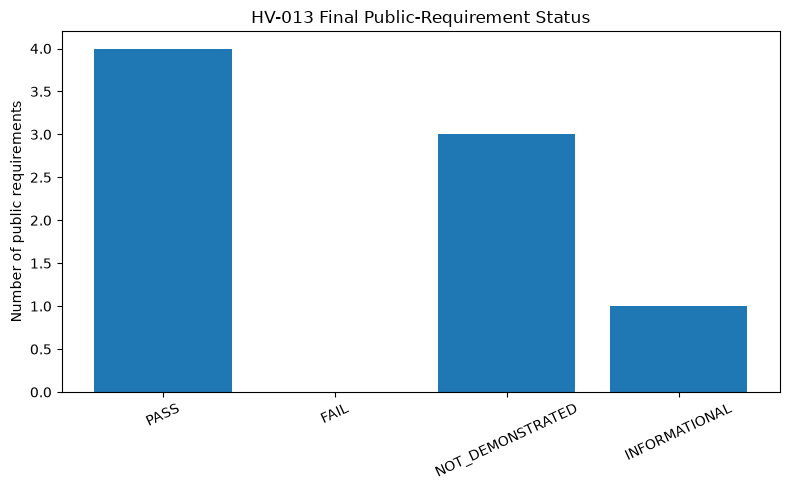

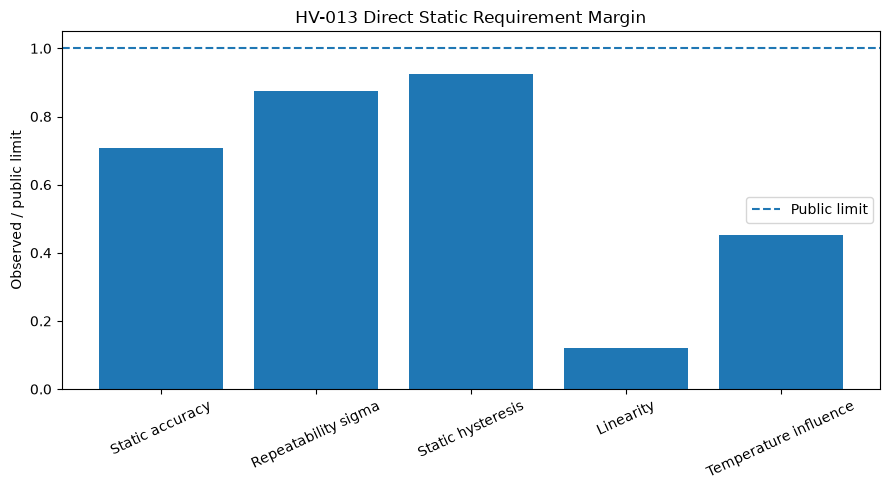

Curated HV-013 figures exported.


In [9]:
# Compliance status
status_order = ["PASS", "FAIL", "NOT_DEMONSTRATED", "INFORMATIONAL"]
status_counts = (
    compliance_matrix_df["Status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(status_counts.index, status_counts.values)
ax.set_ylabel("Number of public requirements")
ax.set_title("HV-013 Final Public-Requirement Status")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(
    figures_dir / "hv013_compliance_status.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Evidence summary: normalized observed/limit ratios for directly comparable metrics
plot_rows = []

for _, row in compliance_matrix_df.iterrows():
    if row["Requirement"] == "Static accuracy":
        limit = limits["static_accuracy_abs_rh_percent"]
    elif row["Requirement"] == "Repeatability sigma":
        limit = limits["repeatability_sigma_max_rh_percent"]
    elif row["Requirement"] == "Static hysteresis":
        limit = limits["hysteresis_max_rh_percent"]
    elif row["Requirement"] == "Linearity":
        limit = limits["linearity_max_rh_percent"]
    elif row["Requirement"] == "Temperature influence":
        limit = limits["temperature_influence_max_rh_percent_per_c"]
    else:
        continue

    plot_rows.append(
        {
            "Requirement": row["Requirement"],
            "Observed_to_Limit": float(row["Observed"]) / float(limit),
        }
    )

normalized_static_df = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    normalized_static_df["Requirement"],
    normalized_static_df["Observed_to_Limit"],
)
ax.axhline(1.0, linestyle="--", label="Public limit")
ax.set_ylabel("Observed / public limit")
ax.set_title("HV-013 Direct Static Requirement Margin")
ax.tick_params(axis="x", rotation=25)
ax.legend()
fig.tight_layout()
fig.savefig(
    figures_dir / "hv013_final_evidence_summary.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Curated HV-013 figures exported.")

## 11. Curated Evidence Export

In [10]:
static_metric_details_df = pd.DataFrame(
    [
        {
            "Metric": "Max_TestID_Repeatability_SD",
            "Value": float(evidence["repeatability_detail"]["Std_Error_RH"].max()),
            "Units": "%RH",
        },
        {
            "Metric": "Repeatability_CommonSigma_UCL95",
            "Value": float(
                compliance_matrix_df.loc[
                    compliance_matrix_df["Requirement"].eq("Repeatability sigma"),
                    "Observed",
                ].iloc[0]
            ),
            "Units": "%RH",
        },
        {
            "Metric": "Pooled_Repeatability_SD",
            "Value": float(
                evidence["rr_summary"].loc[
                    evidence["rr_summary"]["Component"].eq(
                        "Within-Test Repeatability"
                    ),
                    "Value_RH",
                ].iloc[0]
            ),
            "Units": "%RH",
        },
        {
            "Metric": "Max_Static_Hysteresis",
            "Value": float(hysteresis_df["Hysteresis_Abs"].max()),
            "Units": "%RH",
        },
        {
            "Metric": "Linearity_Max_Abs_Deviation",
            "Value": float(linearity_metrics["Max_Abs_Deviation"]),
            "Units": "%RH",
        },
        {
            "Metric": "Temperature_Influence_Max_Abs_Slope",
            "Value": float(temperature_metrics["Max_Abs_Slope_RH_per_C"]),
            "Units": "%RH/degC",
        },
    ]
)

compliance_matrix_df.to_csv(
    tables_dir / "hv013_compliance_matrix.csv",
    index=False,
)
static_metric_details_df.to_csv(
    tables_dir / "hv013_static_metric_details.csv",
    index=False,
)
application_risk_df.to_csv(
    tables_dir / "hv013_application_risk_matrix.csv",
    index=False,
)
final_decision_df.to_csv(
    tables_dir / "hv013_final_decision_summary.csv",
    index=False,
)

print("Curated HV-013 tables exported.")

Curated HV-013 tables exported.


## 12. Initial FA-001 Checkpoint

A clean-kernel Run All should establish:

- FA-01 public acceptance-limit audit PASS;
- FA-02 static metrics PASS;
- FA-03 integrated evidence audit PASS;
- FA-04 public requirement matrix PASS;
- FA-05 application-risk matrix PASS;
- FA-06 final decision logic PASS;
- FA-07 final engineering question answered PASS;
- four curated CSV tables;
- two curated figures.

The next step is final interpretation review and formal FA-001 closure.

## 13. Final Engineering Interpretation

### 13.1 Public-requirement result

The final public-requirement matrix contains:

```text
PASS               = 4
FAIL               = 0
NOT_DEMONSTRATED   = 3
INFORMATIONAL      = 1
```

The four direct PASS results are:

- static accuracy;
- static hysteresis;
- linearity under the frozen project-defined best-fit method;
- temperature influence.

No direct FAIL remains after correcting the repeatability decision rule.

The requirements not demonstrated are:

- repeatability sigma under an unspecified worst-condition statistical decision rule;
- t90;
- annual drift.

The settling-band value is informational because no public maximum settling time is defined.

### 13.2 Static accuracy passes with quantified uncertainty

The most conservative declared uncertainty-evaluation result is:

```text
max(|residual bias| + U_k2) ≈ 1.4129 %RH
```

against:

```text
public static accuracy limit = ±2.0 %RH
```

Thus the frozen C1-calibrated sensor passes the uncertainty-aware static accuracy comparison at the four declared uncertainty-evaluation points.

This is a stronger statement than a comparison based only on mean bias because the result includes the HV-011 expanded uncertainty allowance.

### 13.3 Repeatability is supportive but the strict worst-condition requirement is not demonstrated

HV-005 pooled within-Test_ID repeatability is:

```text
pooled SD = 0.2593 %RH
```

For a common-sigma interpretation across the 120 holds, the one-sided 95% upper confidence limit is approximately:

```text
95% UCL for common sigma ≈ 0.2629 %RH
public limit             = 0.3000 %RH
```

Both values are below the public limit.

The previously used direct rule based on the largest of 120 sample standard deviations is not retained as a compliance FAIL rule. With 60 samples per hold, the maximum sample SD is strongly affected by sampling variability and multiple comparisons.

The public specification does not define the statistical decision rule required to demonstrate a maximum condition-specific sigma across the operating space. Therefore the formal status is:

```text
Repeatability sigma = NOT_DEMONSTRATED
```

The evidence supports good repeatability, but a strict worst-condition compliance claim would require a predefined condition-wise confidence or simultaneous decision rule.

### 13.4 Static hysteresis passes, but with limited margin

Maximum matched static UP/DOWN separation is:

```text
0.9250 %RH
```

against:

```text
limit = 1.0 %RH
```

Therefore static hysteresis passes.

However, the margin is only:

```text
1.000 - 0.925 = 0.075 %RH
```

and independent blind validation confirms a persistent direction split of approximately 0.808 %RH.

Therefore static hysteresis passes under the tested point-estimate metric, but the margin is narrow and no formal guard-band decision rule is defined. Direction dependence remains a material physical characteristic of the DUT.

### 13.5 Linearity passes comfortably under the declared project method

The largest deviation of RH-level mean calibrated residual from the best-fit straight line is:

```text
0.120865 %RH
```

against:

```text
limit = 1.0 %RH
```

This passes with substantial margin.

The result remains explicitly **METHOD-DEFINED** because the public specification does not define endpoint linearity versus best-fit linearity.

### 13.6 Temperature influence passes

The worst RH-conditioned temperature slope is:

```text
0.022608 %RH/°C
```

at:

```text
80 %RH, DOWN direction
```

against:

```text
limit = 0.050 %RH/°C
```

Therefore temperature influence passes with more than a factor-of-two margin.

This RH-conditioned result is preferred over a pooled temperature average because HV-004 demonstrated RH × Temperature interaction behavior.

### 13.7 t90 compliance is not demonstrated

Observed DUT command-to-t90 is approximately:

```text
mean ≈ 112.0 s
max  ≈ 122.9 s
```

against the public limit:

```text
60 s
```

However, the measured reference itself requires approximately 75–81 s to reach t90 under the same chamber step.

Therefore the test stimulus is not sufficiently fast to isolate a direct DUT-only 60-s t90 compliance result.

The DUT does show substantial additional lag relative to the reference, approximately 29–38 s depending on direction, so dynamic response is clearly slow.

The defensible formal status remains:

```text
t90 = NOT_DEMONSTRATED
```

rather than converting an inadequate stimulus into a formal compliance FAIL.

### 13.8 Annual drift compliance is not demonstrated

The public requirement is:

```text
≤ 0.8 %RH/year
```

but the stability campaign covers only 90 days and exhibits strongly non-monotonic behavior.

The descriptive weekly linear slope, if mechanically annualized, would be approximately:

```text
1.62 %RH/year
```

but this extrapolation is not accepted as a valid one-year drift estimate.

Observed 90-day evidence includes:

- maximum center excursion ≈ 0.5025 %RH;
- Day-84 drift ≈ +0.0472 %RH;
- RH-dependent span/shape change ≈ -0.151 %RH.

Therefore:

```text
Drift = NOT_DEMONSTRATED
```

A longer stability campaign or an explicitly specified accelerated-aging model would be required for direct annual-drift compliance.

### 13.9 Dynamic-use risk is the dominant application limitation

The dynamic evidence is much more restrictive than the steady-state static evidence.

Key findings include:

```text
Blind static Direction split       ≈ 0.808 %RH
Ramp C1 Direction separation       ≈ 2.365 %RH
Cyclic Direction/state gap         ≈ 4.692 %RH
Fastest sinusoidal gain            ≈ 0.474
Maximum measured phase lag         ≈ 43.94°
```

The frozen C1 calibration is therefore effective as a global static bias correction but is not a dynamic compensation model.

For slowly varying or steady HVAC monitoring, this limitation may be manageable.

For fast or direction-neutral tracking, it is not.

### 13.10 Final suitability classification

The evidence supports three distinct conclusions:

#### Full public-spec compliance

```text
NOT FULLY DEMONSTRATED
```

because:

- repeatability worst-condition compliance is NOT_DEMONSTRATED under the available decision rule;
- t90 is NOT_DEMONSTRATED;
- annual drift is NOT_DEMONSTRATED.

#### Steady-state/static HVAC use

```text
CONDITIONALLY SUITABLE
```

because:

- uncertainty-aware static accuracy passes;
- static hysteresis passes;
- linearity passes;
- temperature influence passes;
- pooled repeatability and its common-sigma 95% UCL are below the public limit;
- strict worst-condition repeatability is not formally demonstrated because the public decision rule is unspecified;
- stability/drift remains a documented limitation.

#### Dynamic HVAC use

```text
NOT RECOMMENDED AS-IS
```

for applications requiring fast, direction-neutral tracking because step, ramp, cyclic, and sinusoidal evidence all show substantial dynamic state dependence and lag.

### 13.11 Validation-design limitation

Blind validation is independent in the sense that its measurements were not used for fitting, tuning, or model selection. Its scope is nevertheless limited: VALIDATION uses only Day 3 and RH setpoints 30, 50, and 70 %RH, while CALIBRATION uses Days 1–2 and RH setpoints 20, 40, 60, and 80 %RH.

The validation result therefore demonstrates generalization to a new day and to interpolated RH setpoints within the tested 20–80 %RH range. Because Day 3 and the validation role are fully confounded, the observed validation residual cannot be separated cleanly into a day effect and a model-generalization effect.

### 13.12 Final answer to the project engineering question

> **Is the sensor suitable for the intended HVAC measurement application, under the tested operating conditions, after calibration and with quantified measurement uncertainty?**

**Answer: conditionally, for slow or steady-state HVAC monitoring under the tested conditions.**

The frozen C1 calibration successfully reduces global static bias and the sensor meets the uncertainty-aware static accuracy requirement at the declared evaluation points. It also meets the tested static hysteresis, linearity, and temperature-influence limits.

However, an unconditional suitability claim is not supported because strict worst-condition repeatability is not formally demonstrated, annual drift and direct t90 compliance are not demonstrated, and strong direction-dependent dynamic behavior remains.

Therefore the sensor should not be considered fully validated for fast dynamic RH tracking without additional dynamic compensation, improved state awareness, or a different sensor response characteristic.

## 14. FA-001 Gate Decision

**FA-001 = PASS WITH DOCUMENTED CONDITIONS**

This gate evaluates whether the final engineering assessment is complete, reproducible, traceable, and technically defensible. It does **not** mean that every DUT requirement passes.

### Basis for PASS

- all public acceptance limits are loaded unchanged;
- static accuracy is uncertainty-aware;
- strict repeatability is evaluated without hiding the worst observed Test_ID;
- static hysteresis is matched condition-by-condition;
- linearity method is explicitly defined and labeled method-dependent;
- temperature influence preserves RH × Direction structure;
- t90 evidence adequacy is evaluated explicitly;
- settling-band status does not invent a missing maximum-time requirement;
- annual drift is not extrapolated unjustifiably from 90 days;
- dynamic application risks are integrated separately from binary spec compliance;
- final full-spec, static-use, and dynamic-use conclusions are separated;
- no hidden simulator truth is used.

### Documented conditions

1. Repeatability strict maximum is 0.3192 %RH versus a 0.30 %RH public limit.
2. Static hysteresis passes but approaches the 1.0 %RH limit, with maximum observed matched separation 0.925 %RH.
3. Linearity PASS is based on a transparent project-defined best-fit-line method because the public spec does not define the formal test method.
4. t90 compliance is unresolved because the chamber/reference stimulus is slower than the DUT public t90 limit.
5. Annual drift compliance is unresolved because only 90 days of non-monotonic stability evidence are available.
6. Dynamic Direction/state dependence remains strong and materially limits fast-tracking use.
7. HV-011 remains the primary measurement-uncertainty statement; HV-012 is a validation/sensitivity analysis.

### Final project classification

```text
Full public-spec compliance:
NOT FULLY DEMONSTRATED

Steady-state/static HVAC suitability:
CONDITIONALLY SUITABLE

Dynamic HVAC suitability:
NOT RECOMMENDED AS-IS
```

### Analytical project status

After final artifact capture and repository closure:

```text
HV-001 through HV-013 = complete
Core analytical project = complete
Next activity = technical reporting, communication, and future scoped extensions
```